In [13]:
pip install matplotlib # not dependancy of mtex!!!

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pillow-12.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 1.0 MB/s  0:00:10a 0:00:010:00:01:020m
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 603.3 kB/s  0:00:08591.3 kB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 715.6 kB/s  0:00:015.4 kB/s eta 0:00:01
Using cached pillow-12.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (6.9 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib] 6/7 [matplotlib]ow]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import datetime
import numpy as np
from mtex import *

# Sample a texture

In [2]:
# PF plotting conventions
plottingConvention.default('y→↑x')
cs = crystalFrame('m-3m', [4.05, 4.05, 4.05], mineral='Aluminium', color='blue')
ss = specimenFrame('triclinic')
psi = SO3DeLaValleePoussinKernel(halfwidth=7*degree);
hkil = [Miller(0, 0, 1, cs), Miller(1,1,0, cs), Miller(1,1,1, cs)]
cs


crystalFrame (⊙c→a)
  mineral : Aluminium
  color   : blue
  symmetry: m3̅m
  elements: 48
  a, b, c : 4.05, 4.05, 4.05

## Sample a texture from .crc
### (requires adjacent .cpr)

In [3]:

# Import ebsd, apply correction.
eulerCorrection = orientation.byEuler(1*degree, 88*degree, 89*degree)
ebsd = EBSD.load("EBSD.crc", cs, eulerCorrection=eulerCorrection);


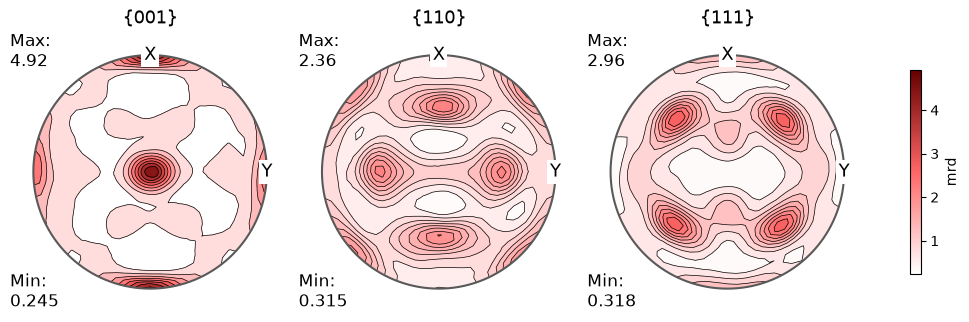

In [4]:

# Plot PFs of original texture
newMtexFigure()
odf = calcDensity(ebsd.orientations, halfwidth=7*degree);
plotPF(odf, hkil, antipodal=True, resolution=5*degree, contourf=True, complete=True, upper=True, minmax=True)
mtexColorMap('LaboTeX')
setColorRange('equal')
mtexColorbar(location='eastoutside', label='mrd', multiple=False)


In [8]:
def MCMC_sampling(odf, cs, psi, max_samples):
    """
    Sample orientations from the ODF
    rejecting any samples which increase the ODF error with original
    minimising ODFerror between original and sample
    """
    samples = odf.discreteSample(n=1)
    odf_rec = calcDensity(samples, psi)
    min_error = calcError(odf, odf_rec)
    error_array = [min_error]

    # Refinement: Add oris that reduce error
    start_time = datetime.datetime.now()
    
    while len(samples) < max_samples:
    
        # Add a sample only if it decreases the error.
        samples, min_error = update_samples(odf, cs, psi, samples, min_error, error_array)
    
    odf_rec = calcDensity(samples, psi)
    
    print(f'Start: {start_time}\n')
    print(f'Finish: {datetime.datetime.now()}\n')
    return odf_rec


def update_samples(odf, cs, psi, samples, min_error, error_array):
    """
    Generate a texture sample and add it to the samples
    """
    sample = odf.discreteSample(n=1)

    # make a temp copy
    temp_samples = samples
    
    # add the new sample to the list
    temp_samples = cat(temp_samples, sample)

    odf_rec = calcDensity(temp_samples, psi)

    error = calcError(odf, odf_rec)

    if error < min_error:

        samples = temp_samples;
        min_error = error;
        print(f'n_samples:{len(samples)}\t error:{min_error}')

    return samples, min_error


odf_rec = MCMC_sampling(odf, cs, psi, 100);


n_samples:2	 error:0.30260031535839776
n_samples:3	 error:0.3011046368775482
n_samples:4	 error:0.30043291813722506
n_samples:5	 error:0.27631293826156533
n_samples:6	 error:0.27425801670755107
n_samples:7	 error:0.2730476399868882
n_samples:8	 error:0.26888096824825836
n_samples:9	 error:0.2679842585520215
n_samples:10	 error:0.26649588689956705
n_samples:11	 error:0.26539184718044717
n_samples:12	 error:0.25589979119176165
n_samples:13	 error:0.2555042512766749
n_samples:14	 error:0.2444169720832531
n_samples:15	 error:0.2424868328231353
n_samples:16	 error:0.24177768896595203
n_samples:17	 error:0.23936899984208077
n_samples:18	 error:0.23877731545304817
n_samples:19	 error:0.238531171774396
n_samples:20	 error:0.2366394591289756
n_samples:21	 error:0.23567717998094576
n_samples:22	 error:0.23052919780408065
n_samples:23	 error:0.22556000959133646
n_samples:24	 error:0.21998563027810064
n_samples:25	 error:0.2194571032402141
n_samples:26	 error:0.2090300382070226
n_samples:27	 error

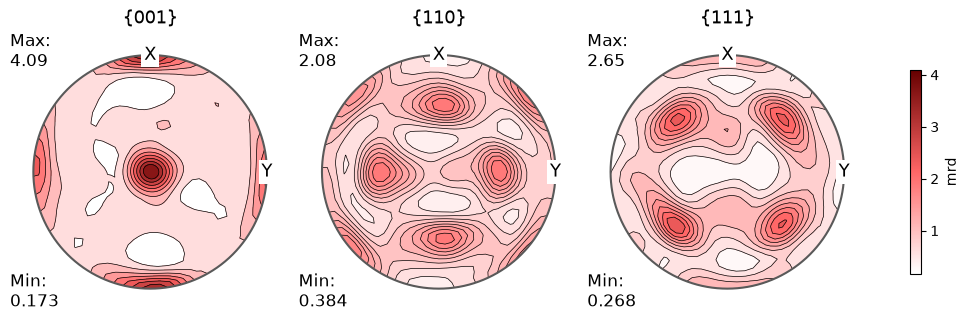

In [9]:

# Plot PFs of sampled texture
newMtexFigure()
plotPF(odf_rec, hkil, antipodal=True, resolution=5*degree, contourf=True, complete=True, upper=True, minmax=True)
mtexColorMap('LaboTeX')
setColorRange('equal')
mtexColorbar(location='eastoutside', label='mrd', multiple=False)
